# Delays and Physical Modeling

Delay lines are the building blocks of echoes, flangers, comb filters, Karplus-Strong strings and reverbs. This notebook builds those structures from primitives, then shows the shipped instruments that use them.

Sources:
- [CLM generators -- delay/comb/all-pass](https://ccrma.stanford.edu/software/snd/snd/sndclm.html)
- [CLM reverb discussion](https://ccrma.stanford.edu/software/snd/snd/sndclm.html)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

import pysndlib.clm as clm
from pysndlib.instruments import pluck, stringy, bouncy

SR = 44100

def spectrum(x, n=8192):
    rl = np.copy(x[:n].astype(float)); im = np.zeros(n)
    clm.mus_fft(rl, im, n, 1)
    clm.mus_rectangular2polar(rl, im)
    return np.abs(rl[:n//2])

## The comb: resonance from feedback

A comb feeds its output back: peaks appear at multiples of SR/size Hz. Sweep the input with noise and watch the resonances:

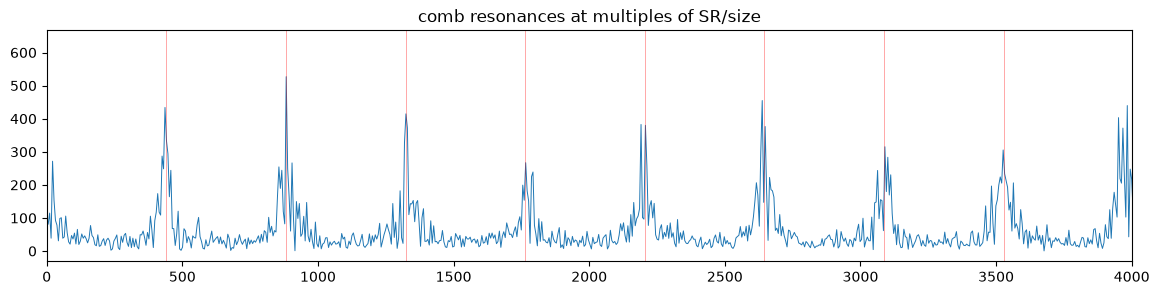

In [3]:
noise = np.random.default_rng(2).uniform(-1, 1, SR)
comb = clm.make_comb(0.85, 100)                       # peaks every 441 Hz
out = np.array([clm.comb(comb, float(x)) for x in noise])

f = np.arange(4096) * SR / 8192
plt.figure(figsize=(14, 3))
plt.plot(f, spectrum(out), lw=0.7)
plt.xlim(0, 4000)
for k in range(1, 9):
    plt.axvline(k * SR / 100, color='red', alpha=0.4, lw=0.6)
plt.title('comb resonances at multiples of SR/size'); plt.show()

## Echo and flanging

A plain delay makes an echo; a delay whose *length* you modulate each sample is a flanger. pysndlib's delay takes the input value and a length change via `delay_tick`-style calls -- here we modulate by rebuilding the delay time through the fm input of `delay`:

In [15]:
with clm.Sound('flange.wav', channels=1, srate=SR):
    d = clm.make_delay(int(0.005 * SR) + 20, max_size=int(0.005 * SR) + 20,
                       interp_type=clm.Interp.LINEAR)
    sweep = clm.make_triangle_wave(3.3, amplitude=10.0)
    nz = clm.make_rand(1200.0)
    for i in range(2 * SR):
        v = clm.rand(nz)
        clm.outa(i, 0.6 * v + 0.4 * clm.delay(d, v, clm.triangle_wave(sweep)))

In [16]:
ipd.Audio('flange.wav', rate=SR)

## Karplus-Strong: the plucked string

A short delay averaged with feedback is a vibrating string (the pluck instrument). Different `weighting` and `lossfact` values change the decay character:

In [17]:
with clm.Sound('strings.wav', channels=1, srate=SR):
    for n, f in enumerate([220.0, 277.2, 330.0, 440.0]):
        pluck(n * 0.5, 1.5, f, 0.4)
    stringy(2.5, 1.5, 330.0, 0.3)
    bouncy(4.0, 1.5, 550.0, 0.3)

In [18]:
ipd.Audio('strings.wav', rate=SR)

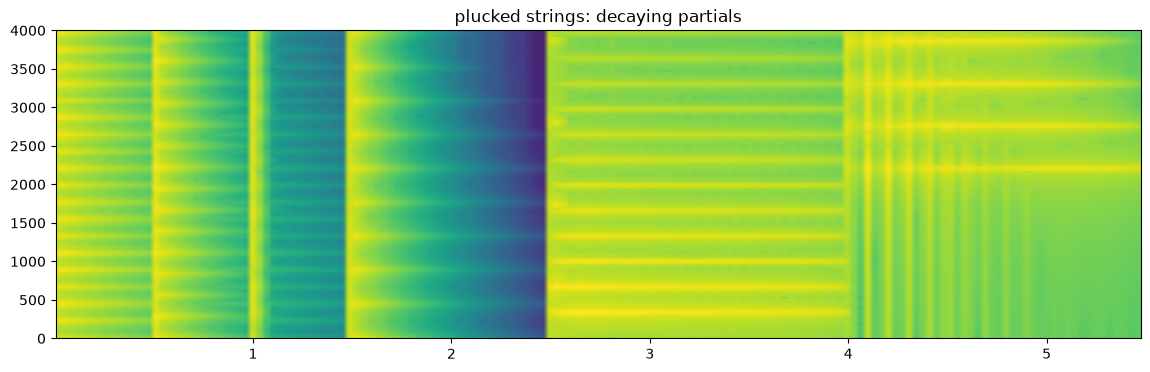

In [19]:
st, _ = clm.file2ndarray('strings.wav')
plt.figure(figsize=(14, 4))
plt.specgram(st[0], NFFT=2048, Fs=SR, noverlap=512)
plt.ylim(0, 4000); plt.title('plucked strings: decaying partials'); plt.show()

## Inside a reverb: comb + all-pass banks

The classic Schroeder/Jordan reverb (jc_reverb) is a bank of 4 parallel combs feeding 3 all-pass filters. We can build the same structure directly and listen to an impulse response:

In [ ]:
with clm.Sound('ir.wav', channels=1, srate=SR):
    combs = clm.make_comb_bank([clm.make_comb(0.742, 4799),
                                clm.make_comb(0.733, 4999),
                                clm.make_comb(0.715, 5399),
                                clm.make_comb(0.697, 5801)])
    passes = clm.make_all_pass_bank([clm.make_all_pass(-0.8, 0.8, 1051),
                                      clm.make_all_pass(-0.8, 0.8, 337),
                                      clm.make_all_pass(-0.8, 0.8, 113)])
    for i in range(SR):
        v = 1.0 if i == 0 else 0.0                    # a single impulse
        clm.outa(i, clm.all_pass_bank(passes, clm.comb_bank(combs, v)))

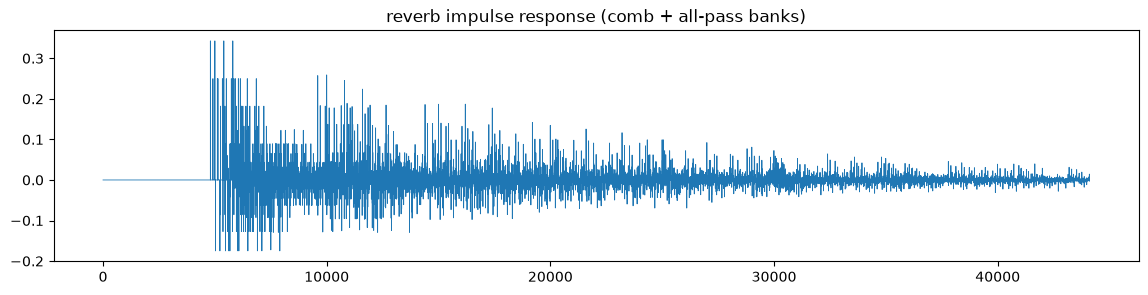

In [22]:
ir, _ = clm.file2ndarray('ir.wav')
plt.figure(figsize=(14, 3))
plt.plot(ir[0], lw=0.6); plt.title('reverb impulse response (comb + all-pass banks)')
plt.show()

In [23]:
ipd.Audio('ir.wav', rate=SR)

Compare with the shipped instrument, which adds decay control and stereo spreading -- see the [spatialization notebook](16_Spatialization_Reverb.ipynb).

## Summary

- Echo, flanging, resonance, strings and reverb are all delay networks
- Comb size sets pitch; feedback sets ring; all-pass adds density

Next: [granular synthesis](12_Granulate.ipynb)